# DE + SVM
Binary FACED classification with subject-disjoint validation and test folds.


## Imports


In [1]:
import hashlib
import json
import pickle
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import sem
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix
from threadpoolctl import threadpool_limits

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding='utf-8')


## Config


In [2]:
variant = 'de'
artifact_root = Path(r'D:\EEG Experiment Artifacts\2026-11-02')
reference_root = artifact_root / 'binary_de_psd'
experiment_root = artifact_root / 'svm_feature_ablation'
run_dir = experiment_root / variant
run_dir.mkdir(parents=True, exist_ok=True)
dataset_root = Path(r'C:\FACED dataset')
run_training = True
seed = 42
n_jobs = 2
C_candidates = 10.0 ** np.arange(-5, 1, 0.5)
max_iter = 10000
tolerance = 1e-4
feature_columns = {'de': list(range(5)), 'psd': list(range(5,10)), 'de_psd': list(range(10))}[variant]
class_names = ['Negative', 'Positive']
selected_videos = np.r_[0:12,16:28]
channels = ['Fp1','Fp2','Fz','F3','F4','F7','F8','FC1','FC2','FC5','FC6',
            'Cz','C3','C4','T7','T8','CP1','CP2','CP5','CP6','Pz','P3','P4',
            'P7','P8','PO3','PO4','Oz','O1','O2']
print('Linear SVM:', variant, '| CPU workers:', n_jobs)
print('C candidates:', C_candidates)
print('C selection uses inner validation subjects only; no refit on validation subjects.')
print('Same inputs, train-only scaling and subject splits as the binary GAT-LSTM experiments.')


Linear SVM: de | CPU workers: 2
C candidates: [1.00000000e-05 3.16227766e-05 1.00000000e-04 3.16227766e-04
 1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00]
C selection uses inner validation subjects only; no refit on validation subjects.
Same inputs, train-only scaling and subject splits as the binary GAT-LSTM experiments.


## Data


In [3]:
feature_files = {kind: [dataset_root/'EEG_Features'/kind/f'sub{s:03d}.pkl.pkl' for s in range(123)]
                 for kind in ['DE','PSD']}
input_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest()
                for group in feature_files.values() for p in group}
extractor = dataset_root/'EEG_Features/features_extract.py'
input_hashes[str(extractor)] = hashlib.sha256(extractor.read_bytes()).hexdigest()
cache_dir = reference_root/'cache'
cache_dir.mkdir(parents=True, exist_ok=True)
feature_path = cache_dir/'features.npy'
if not feature_path.exists():
    values = np.empty((123,24,30,30,10),dtype=np.float32)
    for sub in range(123):
        for kind,columns in [('DE',slice(0,5)),('PSD',slice(5,10))]:
            with feature_files[kind][sub].open('rb') as f:
                x = np.asarray(pickle.load(f))
            assert x.shape == (28,32,30,5) and np.isfinite(x).all()
            x = x[selected_videos,:30].transpose(0,2,1,3)
            if kind == 'PSD':
                assert (x >= 0).all()
                x = np.log(np.maximum(x,1e-20))
            values[sub,...,columns] = x
    np.save(feature_path,values.reshape(2952,30,30,10))
    del values
cache_hash = hashlib.sha256(feature_path.read_bytes()).hexdigest()
features = np.load(feature_path,mmap_mode='r')
assert features.shape == (2952,30,30,10) and np.isfinite(features).all()
subjects = np.repeat(np.arange(123),24)
videos = np.tile(selected_videos+1,123)
video_labels = np.r_[np.zeros(12,dtype=int),np.ones(12,dtype=int)]
trial_labels = np.tile(video_labels,123)
splits = []
for fold in range(10):
    test = np.arange(fold*12,(fold+1)*12 if fold<9 else 123)
    remaining = np.setdiff1d(np.arange(123),test)
    shuffled = np.random.default_rng(seed+fold).permutation(remaining)
    n_val = round(0.2*len(remaining))
    val,train = np.sort(shuffled[:n_val]),np.sort(shuffled[n_val:])
    assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    splits.append({'fold':fold,'train':train.tolist(),'val':val.tolist(),'test':test.tolist()})
assert sorted(sub for split in splits for sub in split['test']) == list(range(123))
reference_path = reference_root/'protocol.json'
if reference_path.exists():
    reference = json.loads(reference_path.read_text())
    assert reference['splits'] == splits
    assert reference['input_hashes'] == input_hashes
    assert reference['cache_sha256'] == cache_hash
    assert reference['settings']['channels'] == channels
    assert reference['settings']['selected_video_ids'] == (selected_videos+1).tolist()
settings = {
    'seed':seed, 'C_candidates':C_candidates.tolist(), 'dual':False,
    'loss':'squared_hinge', 'penalty':'l2', 'max_iter':max_iter, 'tol':tolerance,
    'features':'official FACED DE; natural log PSD with floor 1e-20',
    'psd_definition':'released globally normalized FFT/Hann features, not a new Welch estimate',
    'feature_order':'channel-major, then band; concatenated DE/log-PSD within each channel',
    'scaling':'per channel/feature training mean and std, floor 1e-6; float32 transform',
    'channels':channels, 'selected_video_ids':(selected_videos+1).tolist(),
    'bands':[[1,4],[4,8],[8,14],[14,30],[30,47]],
    'labels':'12 negative and 12 positive fixed-stimulus videos; neutral excluded',
    'selection':'maximum inner validation balanced accuracy; ties use smallest C',
    'refit_validation':False, 'test_evaluation':'once after C selection, one prediction per second',
    'normalization_and_smoothing':'no running normalization or LDS',
    'score':'uncalibrated SVM decision margin; not a probability'
}
protocol = {'settings':settings,'splits':splits,'input_hashes':input_hashes,'cache_sha256':cache_hash}
protocol_hash = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
protocol_path = experiment_root/'protocol.json'
if protocol_path.exists():
    assert json.loads(protocol_path.read_text()) == protocol
else:
    save_json(protocol_path,protocol)
print('Subjects: 123 | trials: 2952 | one-second targets: 88560')
print('Features per second:',30*len(feature_columns))
print('Binary trial counts:',np.bincount(trial_labels))


Subjects: 123 | trials: 2952 | one-second targets: 88560
Features per second: 150
Binary trial counts: [1476 1476]


## Preprocessing and SVM


In [4]:
def trial_indices(people):
    return np.flatnonzero(np.isin(subjects,people))

def fit_scaler(split):
    directory = experiment_root/'scalers'
    directory.mkdir(exist_ok=True)
    path = directory/f"fold_{split['fold']:02d}.npz"
    if path.exists():
        saved = np.load(path)
        assert saved['protocol_hash'].item() == protocol_hash
        assert np.array_equal(saved['training_subjects'],split['train'])
        return saved['mean'],saved['std']
    x = features[trial_indices(split['train'])]
    mean = x.mean(axis=(0,1),dtype=np.float64).astype(np.float32)
    std = np.maximum(x.std(axis=(0,1),dtype=np.float64),1e-6).astype(np.float32)
    reference_scaler = reference_root/'scalers'/f"fold_{split['fold']:02d}.npz"
    if reference_scaler.exists():
        saved = np.load(reference_scaler)
        assert np.array_equal(mean,saved['mean']) and np.array_equal(std,saved['std'])
    np.savez(path,mean=mean,std=std,training_subjects=split['train'],protocol_hash=protocol_hash)
    return mean,std

def prepare(indices,scaler):
    x = (features[indices].copy()-scaler[0])/scaler[1]
    x = np.take(x,feature_columns,axis=-1)
    x = np.ascontiguousarray(x.reshape(-1,30*len(feature_columns)),dtype=np.float64)
    y = np.repeat(trial_labels[indices],30)
    assert np.isfinite(x).all() and set(np.unique(y)) == {0,1}
    return x,y

def metrics(y,pred,score):
    return {'accuracy':float(accuracy_score(y,pred)),
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,average='macro')),
            'roc_auc':float(roc_auc_score(y,score))}

def fit_candidate(c,x_train,y_train,x_val,y_val,fold_seed):
    start = time.perf_counter()
    model = LinearSVC(C=float(c),dual=False,penalty='l2',loss='squared_hinge',
                      max_iter=max_iter,tol=tolerance,random_state=fold_seed)
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter('always',ConvergenceWarning)
        model.fit(x_train,y_train)
    convergence = [str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
    if convergence:
        raise RuntimeError('SVM did not converge: '+str(convergence))
    pred = model.predict(x_val)
    score = model.decision_function(x_val)
    row = {'C':float(c),'seconds':time.perf_counter()-start,'n_iter':int(model.n_iter_),
           **{'val_'+k:v for k,v in metrics(y_val,pred,score).items()}}
    return model,row


## Cross-validation


In [5]:
def run_fold(split):
    fold = split['fold']
    folder = run_dir/f'fold_{fold:02d}'
    folder.mkdir(exist_ok=True)
    config = {'protocol_hash':protocol_hash,'variant':variant,'feature_columns':feature_columns,
              'n_features':30*len(feature_columns),'fold':fold,'settings':settings,
              'sklearn':sklearn.__version__,'numpy':np.__version__}
    config_path = folder/'config.json'
    if config_path.exists():
        assert json.loads(config_path.read_text()) == config
    else:
        save_json(config_path,config)
    if (folder/'metrics.json').exists():
        assert (folder/'model.joblib').exists() and (folder/'predictions.npz').exists()
        print('Restored completed fold',fold,flush=True)
        return json.loads((folder/'metrics.json').read_text())
    start = time.perf_counter()
    train_idx,val_idx,test_idx = [trial_indices(split[k]) for k in ['train','val','test']]
    np.savez(folder/'split_indices.npz',train=train_idx,val=val_idx,test=test_idx)
    scaler = fit_scaler(split)
    x_train,y_train = prepare(train_idx,scaler)
    x_val,y_val = prepare(val_idx,scaler)
    best_model,best_row = None,None
    rows = []
    temp = experiment_root/'parallel_cache'
    temp.mkdir(exist_ok=True)
    with joblib.parallel_config(backend='loky',n_jobs=n_jobs,inner_max_num_threads=1):
        candidates = joblib.Parallel(return_as='generator_unordered',temp_folder=str(temp),max_nbytes='10M')(
            joblib.delayed(fit_candidate)(c,x_train,y_train,x_val,y_val,seed+fold) for c in C_candidates)
        for model,row in candidates:
            rows.append(row)
            pd.DataFrame(rows).sort_values('C').to_csv(folder/'validation_grid.csv',index=False)
            key = (row['val_balanced_accuracy'],-row['C'])
            best_key = (best_row['val_balanced_accuracy'],-best_row['C']) if best_row else (-1,0)
            if key > best_key:
                best_model,best_row = model,row
            print(f"{variant} fold {fold}: C={row['C']:.6g}, val BAcc={row['val_balanced_accuracy']:.4f}",flush=True)
    # No test data are used above to choose C or fit the model/scaler.
    x_test,y_test = prepare(test_idx,scaler)
    decision = best_model.decision_function(x_test)
    predicted = (decision>0).astype(np.int64)
    assert np.array_equal(predicted,best_model.predict(x_test))
    test_metrics = metrics(y_test,predicted,decision)
    joblib.dump(best_model,folder/'model.joblib')
    np.savez_compressed(folder/'predictions.npz',predictions=predicted.reshape(-1,30),
                        labels=y_test.reshape(-1,30),decision=decision.reshape(-1,30),
                        subjects=subjects[test_idx],videos=videos[test_idx])
    np.savetxt(folder/'confusion_matrix.csv',confusion_matrix(y_test,predicted,labels=[0,1]),fmt='%d',delimiter=',')
    result = {'fold':fold,'test_subjects':split['test'],'best_C':best_row['C'],
              'validation':{k.removeprefix('val_'):v for k,v in best_row.items() if k.startswith('val_')},
              'test':test_metrics,'seconds':time.perf_counter()-start}
    save_json(folder/'metrics.json',result)
    print('FOLD COMPLETE',json.dumps(result),flush=True)
    return result

def summarize():
    predictions = np.full((123,24,30),-1,dtype=np.int64)
    decisions = np.full((123,24,30),np.nan,dtype=np.float64)
    fold_results = []
    for split in splits:
        folder = run_dir/f"fold_{split['fold']:02d}"
        fold_results.append(json.loads((folder/'metrics.json').read_text()))
        saved = np.load(folder/'predictions.npz')
        for sub in split['test']:
            mask = saved['subjects']==sub
            assert np.array_equal(saved['videos'][mask],selected_videos+1)
            predictions[sub] = saved['predictions'][mask]
            decisions[sub] = saved['decision'][mask]
    targets = np.tile(np.repeat(video_labels[:,None],30,axis=1)[None],(123,1,1))
    assert (predictions>=0).all() and np.isfinite(decisions).all()
    people = [{'subject':s,**metrics(targets[s].ravel(),predictions[s].ravel(),decisions[s].ravel())} for s in range(123)]
    pd.DataFrame(people).to_csv(run_dir/'subject_metrics.csv',index=False)
    np.savez_compressed(run_dir/'out_of_fold_predictions.npz',predictions=predictions,labels=targets,decision=decisions)
    matrix = confusion_matrix(targets.ravel(),predictions.ravel(),labels=[0,1])
    np.savetxt(run_dir/'confusion_matrix.csv',matrix,fmt='%d',delimiter=',')
    result = {'variant':variant,'protocol_hash':protocol_hash,'n_features':30*len(feature_columns),
              **metrics(targets.ravel(),predictions.ravel(),decisions.ravel()),
              'subject_accuracy_sem':float(sem([p['accuracy'] for p in people])),
              'subjects':123,'one_second_predictions':int(targets.size),'folds':fold_results,
              'total_fold_seconds':sum(f['seconds'] for f in fold_results)}
    save_json(run_dir/'summary.json',result)
    return result


## Train


In [6]:
timing_path = experiment_root/'timing_profile.json'
if timing_path.exists():
    timing = json.loads(timing_path.read_text())
    estimate = sum(t['seconds'] for t in timing if t['variant']==variant)*4*10
    print('Approximate sequential fit minutes:',round(estimate/60,1))
    print('Two CPU workers are used; timing depends on CPU contention and fold conditioning.')
if run_training:
    for split in splits:
        run_fold(split)
    results = summarize()
else:
    results = json.loads((run_dir/'summary.json').read_text())
print('Completed:',variant)


Approximate sequential fit minutes: 4.4
Two CPU workers are used; timing depends on CPU contention and fold conditioning.
de fold 0: C=1e-05, val BAcc=0.5531
de fold 0: C=3.16228e-05, val BAcc=0.5524
de fold 0: C=0.0001, val BAcc=0.5477
de fold 0: C=0.000316228, val BAcc=0.5421
de fold 0: C=0.001, val BAcc=0.5391
de fold 0: C=0.00316228, val BAcc=0.5350
de fold 0: C=0.01, val BAcc=0.5348
de fold 0: C=0.0316228, val BAcc=0.5350
de fold 0: C=0.1, val BAcc=0.5347
de fold 0: C=0.316228, val BAcc=0.5347
de fold 0: C=1, val BAcc=0.5347
de fold 0: C=3.16228, val BAcc=0.5347
FOLD COMPLETE {"fold": 0, "test_subjects": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], "best_C": 1e-05, "validation": {"accuracy": 0.5530934343434344, "balanced_accuracy": 0.5530934343434344, "macro_f1": 0.5526671119037021, "roc_auc": 0.5709086445260687}, "test": {"accuracy": 0.5585648148148148, "balanced_accuracy": 0.5585648148148148, "macro_f1": 0.5576071075935511, "roc_auc": 0.5752450381515775}, "seconds": 19.66066560000035

## Results


In [7]:
oof = np.load(run_dir/'out_of_fold_predictions.npz')
predictions,targets = oof['predictions'],oof['labels']
subject_results = pd.read_csv(run_dir/'subject_metrics.csv')
assert predictions.shape == targets.shape == (123,24,30)
assert np.isclose((predictions==targets).mean(),results['accuracy'])
print(pd.Series({k:100*results[k] for k in ['accuracy','subject_accuracy_sem','balanced_accuracy','macro_f1','roc_auc']}).round(2).to_string())
print(pd.DataFrame([{'fold':f['fold'],'best_C':f['best_C'],'test_accuracy':f['test']['accuracy']} for f in results['folds']]).to_string(index=False))
print('Balanced classes; constant-class baseline: 50%.')
print('C selected using subject-disjoint validation. Test subjects are held out from fitting and selection.')
print('Linear SVM without running normalization/LDS; this is not an exact reproduction of the paper.')
print('ROC-AUC uses uncalibrated decision scores; no probability calibration was fit.')


accuracy                54.79
subject_accuracy_sem     0.42
balanced_accuracy       54.79
macro_f1                54.79
roc_auc                 56.35
 fold   best_C  test_accuracy
    0 0.000010       0.558565
    1 0.000032       0.528588
    2 0.000010       0.551620
    3 0.000100       0.551620
    4 0.000032       0.560880
    5 0.000032       0.565741
    6 0.000100       0.535417
    7 0.001000       0.551042
    8 0.100000       0.529861
    9 0.000010       0.546389
Balanced classes; constant-class baseline: 50%.
C selected using subject-disjoint validation. Test subjects are held out from fitting and selection.
Linear SVM without running normalization/LDS; this is not an exact reproduction of the paper.
ROC-AUC uses uncalibrated decision scores; no probability calibration was fit.


## Plots


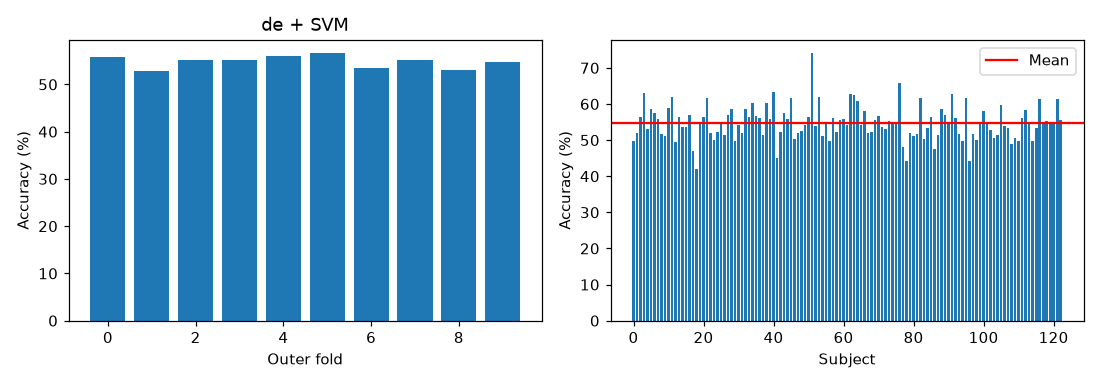

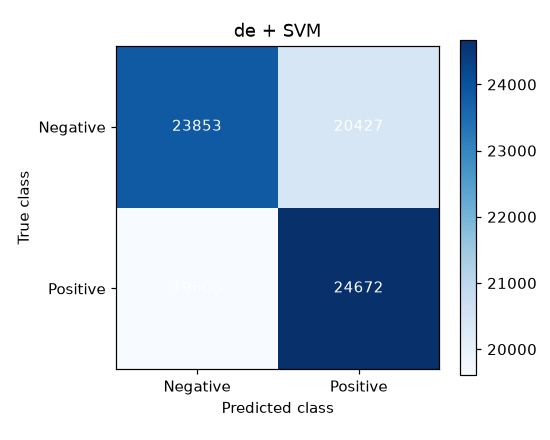

In [8]:
fig,axes = plt.subplots(1,2,figsize=(10,3.5))
axes[0].bar(np.arange(10),[100*f['test']['accuracy'] for f in results['folds']])
axes[0].set(xlabel='Outer fold',ylabel='Accuracy (%)',title=variant+' + SVM')
axes[1].bar(subject_results['subject'],100*subject_results['accuracy'])
axes[1].axhline(100*results['accuracy'],color='red',label='Mean')
axes[1].set(xlabel='Subject',ylabel='Accuracy (%)')
axes[1].legend()
fig.tight_layout()
plt.show()

matrix = confusion_matrix(targets.ravel(),predictions.ravel(),labels=[0,1])
fig,ax = plt.subplots(figsize=(5,4))
image = ax.imshow(matrix,cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted class',ylabel='True class',title=variant+' + SVM')
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
fig.colorbar(image,ax=ax)
fig.tight_layout()
plt.show()
